# LexFront — Review 1 (Modules 1 and 2)

**Question.** Can a compiler-style lexical analyzer (token classes as regexes → Thompson NFA → DFA → minimized DFA,
with a symbol table and error recovery) work as a *pre-tokenizer* for noisy English text classification,
compared with existing tokenizers when everything downstream is held fixed?

**This notebook.** Module 1 = data + existing tokenizers + classifiers. Module 2 = LexFront itself.
It contains no logic: all code lives in `experiments/` and `lexer/`; the notebook calls it and shows results.
Every number shown is read from a JSON file written by a script that ran.

**`QUICK_MODE`** (next cell) keeps the whole notebook under about 10 minutes on a CPU runtime by using a fixed-seed
subsample of each dataset. Set it to `False` to rerun on the full data (much slower).
The committed full-data results are shown in the appendix at the end.

In [1]:
# 1. Get the code, install dependencies (requirements.txt: version ranges), download NLTK data.
import os, subprocess, sys
REPO_URL = os.environ.get("LEXFRONT_REPO_URL", "https://github.com/PavitranVC/lexfront-dfa-tokenizer.git")   # env: CI/tests
REPO_DIR = "lexfront-dfa-tokenizer"

def find_repo_root():
    """The repo root at or above the working directory, or None."""
    here = os.getcwd()
    while here != os.path.dirname(here):
        if os.path.exists(os.path.join(here, "requirements.txt")) and os.path.exists(os.path.join(here, "lexer", "token_spec.py")):
            return here
        here = os.path.dirname(here)

def update_checkout():
    """Fast-forward the clone to origin. A finished run rewrites tracked files (results/quick/...) and that blocks a plain
    pull, so the local changes are set aside with `git stash` (kept: `git stash list`) and the pull is repeated."""
    def git(*args):
        return subprocess.run(["git", "-c", "user.name=colab", "-c", "user.email=colab@localhost", *args],
                              capture_output=True, text=True)
    pull = git("pull", "-q", "--ff-only")
    if pull.returncode != 0 and git("stash", "push", "--include-untracked", "-q").returncode == 0:
        print("local changes from an earlier run were set aside (git stash list) so the code could be updated")
        pull = git("pull", "-q", "--ff-only")
    if pull.returncode != 0:
        raise RuntimeError("could not update the existing clone, so it would run old code under this newer notebook.\n"
                           f"Delete the folder (!rm -rf {os.getcwd()}) and run this cell again.\n" + pull.stderr.strip())

root = find_repo_root()
if root is not None:                               # running inside a checkout (local, CI)
    os.chdir(root)
elif os.path.isdir(REPO_DIR):                      # Colab after a restart or a new session: already cloned
    os.chdir(REPO_DIR)
    update_checkout()                              # old code under this newer notebook would fail further down
else:                                              # fresh Colab runtime: clone the repo
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir(REPO_DIR)
if not os.path.exists(os.path.join("lexer", "token_spec.py")):
    raise RuntimeError(f"{os.getcwd()} is not a complete checkout: delete it and run this cell again")
print("working directory:", os.getcwd())
sys.path.insert(0, os.getcwd())
for name in [m for m in sys.modules if m.split(".")[0] in ("experiments", "lexer", "subword")]:
    del sys.modules[name]                          # re-run in a live kernel: do not keep the old code imported

from experiments import setup_check               # standard library only
before_install = setup_check.snapshot()
%pip install -q -r requirements.txt
setup_check.report_after_install(before_install)  # prints versions in use; warns if a restart is needed
import nltk
for package in ["punkt_tab"]:                      # what word_tokenize needs; a failed download must not pass silently
    try:
        nltk.data.find(f"tokenizers/{package}")
    except LookupError:
        nltk.download(package, quiet=True)
        nltk.data.find(f"tokenizers/{package}")    # raises LookupError with the download hint if it is still missing

working directory: /home/user/lexfront-dfa-tokenizer



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
versions in use: numpy 2.4.6, pandas 3.0.6, scikit-learn 1.9.1


In [2]:
QUICK_MODE = True      # True: fixed-seed subsample (fast).  False: full datasets (slow).
FORCE = QUICK_MODE     # recompute every run even if a cached JSON matches (cheap in QUICK_MODE)
# Files each mode rewrites:
#   True : everything under results/quick/ (the committed results/ is untouched).
#   False: in the committed results/: datasets.json, module2/dfa_states.json + dfa_min.dot/.png, module2/intrinsic__*.json
#          (always, new timestamps and throughput), stats/bootstrap.json, ablation/stats/bootstrap.json,
#          bpe/stats/bootstrap.json, subword2/stats/bootstrap.json, tables/ and figures/ (rebuilt from the JSON); module1/, module2/, ablation/ and
#          bpe/ and subword2/ run JSONs and their predictions/
#          sidecars only where the fingerprint no longer matches (FORCE is False). `git checkout results/` undoes it.

import pandas as pd
from IPython.display import Image, Markdown, display
from experiments import review1, report
from experiments.observations import observation
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
RES = review1.results_dir(QUICK_MODE)
print("QUICK_MODE =", QUICK_MODE, "| FORCE =", FORCE, "| results written to", RES)

QUICK_MODE = True | FORCE = True | results written to results/quick


## 1. Datasets

Three Hugging Face datasets, each reduced to *train texts, test texts, labels, label names*:

* `cardiffnlp/tweet_topic_single` — tweets, 6 topics (COLING 2022 split pair when the dataset card confirms it).
* `google-research-datasets/go_emotions` (`simplified`) — Reddit comments; only single-label examples are kept.
* `fancyzhx/ag_news` — news snippets, 4 topics.

The cell loads all three, saves `datasets.json`, and shows the table built from it.

In [3]:
review1.run_datasets_section(QUICK_MODE)
display(Markdown(report.table_datasets(RES)))

/tmp/claude-0/-home-user-lexfront-dfa-tokenizer/bac9101d-3a3e-566d-9970-323539442c9d/scratchpad/venv311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded tweet_topic: train=2000 test=500 labels=6


loaded go_emotions: train=2000 test=500 labels=28


loaded ag_news: train=2000 test=500 labels=4


| dataset | source | train split | test split | train docs | test docs | labels | largest test class % | subsample |
|---|---|---|---|---|---|---|---|---|
| tweet_topic | cardiffnlp/tweet_topic_single | train_coling2022 | test_coling2022 | 2000 | 500 | 6 | 39.60 | train<=2000, test<=500, seed 0 |
| go_emotions | google-research-datasets/go_emotions (simplified) | train | test | 2000 | 500 | 28 | 34.80 | train<=2000, test<=500, seed 0 |
| ag_news | fancyzhx/ag_news | train | test | 2000 | 500 | 4 | 28.40 | train<=2000, test<=500, seed 0 |

### Observations — datasets

In [4]:
display(Markdown(observation("datasets", RES)))

- **tweet_topic**: 2000 train / 500 test documents, 6 labels; the largest test class holds 39.60% of the test set.
- **go_emotions**: 2000 train / 500 test documents, 28 labels; the largest test class holds 34.80% of the test set.
- **ag_news**: 2000 train / 500 test documents, 4 labels; the largest test class holds 28.40% of the test set.

## 2. Module 1 — existing tokenizers and classifiers

Three tokenizers behind one interface `tokenize(text) -> list[str]`: whitespace split, NLTK `word_tokenize`,
NLTK `TweetTokenizer`. Their tokens feed the *same* TF-IDF vectorizer (`tokenizer=fn`, `token_pattern=None`), then a
majority-class baseline, Multinomial Naive Bayes (the method of the base paper) and Logistic Regression.
Metrics: accuracy and macro-F1. Each run is saved to `results/.../module1/*.json` with its full configuration and a
fingerprint of that configuration and of the code; a saved run is reused only while the fingerprint still matches
(`FORCE = True` recomputes everything).

== tweet_topic: train=2000 test=500 labels=6
tweet_topic  whitespace majority acc=0.3960 f1=0.0946
tweet_topic  whitespace nb       acc=0.6380 f1=0.2573


tweet_topic  whitespace lr       acc=0.6560 f1=0.3078


tweet_topic  nltk       majority acc=0.3960 f1=0.0946
tweet_topic  nltk       nb       acc=0.6620 f1=0.2664
tweet_topic  nltk       lr       acc=0.6620 f1=0.3170


tweet_topic  tweet      majority acc=0.3960 f1=0.0946
tweet_topic  tweet      nb       acc=0.6640 f1=0.2677
tweet_topic  tweet      lr       acc=0.6540 f1=0.3105


== go_emotions: train=2000 test=500 labels=28
go_emotions  whitespace majority acc=0.3480 f1=0.0191
go_emotions  whitespace nb       acc=0.3540 f1=0.0264


...

go_emotions  tweet      lr       acc=0.4300 f1=0.1394


== ag_news: train=2000 test=500 labels=4
ag_news      whitespace majority acc=0.2420 f1=0.0974
ag_news      whitespace nb       acc=0.8680 f1=0.8673
ag_news      whitespace lr       acc=0.8480 f1=0.8472


ag_news      nltk       majority acc=0.2420 f1=0.0974
ag_news      nltk       nb       acc=0.8740 f1=0.8729
ag_news      nltk       lr       acc=0.8580 f1=0.8569


ag_news      tweet      majority acc=0.2420 f1=0.0974
ag_news      tweet      nb       acc=0.8800 f1=0.8797
ag_news      tweet      lr       acc=0.8600 f1=0.8585


| dataset | tokenizer | Majority acc / F1 | Naive Bayes acc / F1 | Logistic Reg. acc / F1 |
|---|---|---|---|---|
| tweet_topic | whitespace | 39.60 / 9.46 | 63.80 / 25.73 | 65.60 / 30.78 |
| tweet_topic | nltk | 39.60 / 9.46 | 66.20 / 26.64 | 66.20 / 31.70 |
| tweet_topic | tweet | 39.60 / 9.46 | 66.40 / 26.77 | 65.40 / 31.05 |
| go_emotions | whitespace | 34.80 / 1.91 | 35.40 / 2.64 | 41.00 / 10.58 |
| go_emotions | nltk | 34.80 / 1.91 | 35.60 / 2.91 | 43.00 / 13.90 |
| go_emotions | tweet | 34.80 / 1.91 | 35.60 / 2.91 | 43.00 / 13.94 |
| ag_news | whitespace | 24.20 / 9.74 | 86.80 / 86.73 | 84.80 / 84.72 |
| ag_news | nltk | 24.20 / 9.74 | 87.40 / 87.29 | 85.80 / 85.69 |
| ag_news | tweet | 24.20 / 9.74 | 88.00 / 87.97 | 86.00 / 85.85 |

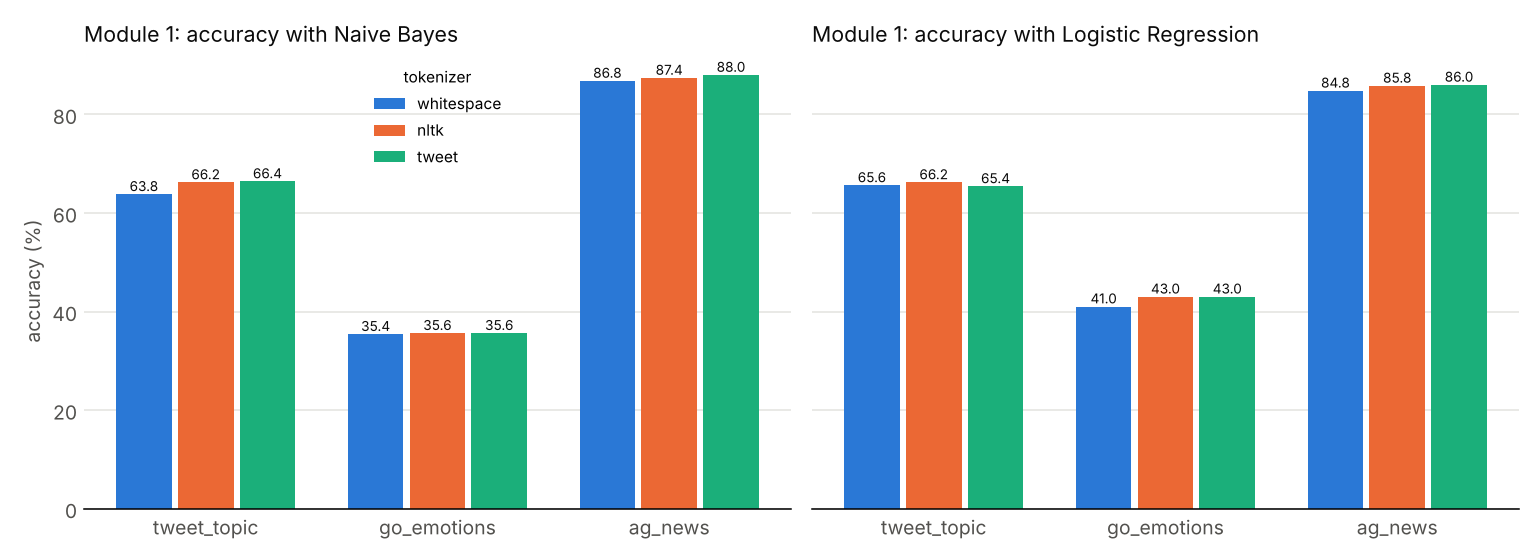

In [5]:
review1.run_module1_section(QUICK_MODE, force=FORCE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["module1_results"]))
display(Image(f"{RES}/figures/module1_accuracy.png"))

### Observations — Module 1

In [6]:
display(Markdown(observation("module1", RES)))

- **tweet_topic**: best accuracy 66.40% (tweet + NB). Across the three tokenizers LR is +0.27 points vs NB on average; the tokenizer spread is 0.80 points under LR and 2.60 points under NB.
- **go_emotions**: best accuracy 43.00% (nltk + LR). Across the three tokenizers LR is +6.80 points vs NB on average; the tokenizer spread is 2.00 points under LR and 0.20 points under NB.
- **ag_news**: best accuracy 88.00% (tweet + NB). Across the three tokenizers LR is -1.87 points vs NB on average; the tokenizer spread is 1.20 points under LR and 1.20 points under NB.

_One training run per cell (seed 0). The 95% confidence intervals (table `ci_table`, file `stats/bootstrap.json`) are percentile bootstraps over the test examples: they show how much a score moves with the draw of the test set, not with training randomness, which one run per cell cannot show (the NB and LR fits are deterministic; the full grid uses no subsampling, QUICK mode one fixed-seed subsample). A gap whose CI includes 0 should not be read as a real difference. Gaps not in `ci_table` (e.g. spreads between baselines, LR vs NB) have no paired CI and are untested; overlapping per-run CIs (`ci_runs`) are not a test of a difference._

## 3. Module 2 — LexFront

LexFront is a lexer written the way a compiler front end is: **token classes in priority order**
(URL, MENTION, HASHTAG, EMOTICON, EMOJI, NUMBER, CONTRACTION, ELONGATED, WORD, PUNCT, and UNKNOWN as the error-recovery
fallback), **longest match with ties to the earlier rule** (PLY), then a **normalizer** (URL→`<URL>`, MENTION→`<USER>`,
NUMBER→`<NUM>`, elongated letters collapsed, WORD lowercased, slang lookup) and a **symbol table**.

### 3a. Side-by-side on eight example tweets
First the plain token lists of all four tokenizers (input lowercased, as the vectorizer does), then LexFront's
class / lexeme / normalized form for each tweet.

In [7]:
display(review1.compare_tokenizers())

,#,whitespace,nltk,tweet,lexfront
0,1,[omg] [u] [wont] [believe] [this!!!] [https://t.co/abc123] [@mike_93] [:)],[omg] [u] [wont] [believe] [this] [!] [!] [!] [https] [:] [//t.co/abc123] [@] [mike_93] [:] [)],[omg] [u] [wont] [believe] [this] [!] [!] [!] [https://t.co/abc123] [@mike_93] [:)],[oh] [my] [god] [you] [wont] [believe] [this] [!] [!] [!] [<URL>] [<USER>] [:)]
1,2,[sooooo] [tired] [of] [mondays] [#monday] [#ugh] [😩😩],[sooooo] [tired] [of] [mondays] [#] [monday] [#] [ugh] [😩😩],[sooooo] [tired] [of] [mondays] [#monday] [#ugh] [😩] [😩],[soo] [tired] [of] [mondays] [#monday] [#ugh] [😩] [😩]
2,3,"[can't] [wait] [for] [the] [game] [tonight,] [we're] [gonna] [win] [3-0] [<3]","[ca] [n't] [wait] [for] [the] [game] [tonight] [,] [we] ['re] [gon] [na] [win] [3-0] [<] [3]","[can't] [wait] [for] [the] [game] [tonight] [,] [we're] [gonna] [win] [3-0] [<3]","[can't] [wait] [for] [the] [game] [tonight] [,] [we're] [going] [to] [win] [<NUM>] [-] [<NUM>] [<3]"
3,4,"[idk] [tbh...] [this] [movie] [was] [gr8] [but] [the] [ending,] [meh] [:-(]","[idk] [tbh] [...] [this] [movie] [was] [gr8] [but] [the] [ending] [,] [meh] [:] [-] [(]","[idk] [tbh] [...] [this] [movie] [was] [gr8] [but] [the] [ending] [,] [meh] [:-(]","[i] [do] [not] [know] [to] [be] [honest] [.] [.] [.] [this] [movie] [was] [great] [but] [the] [ending] [,] [meh] [:-(]"
4,5,"[@jenny] [thx] [4] [the] [1,200] [likes] [lolll] [#blessed] [🙏]","[@] [jenny] [thx] [4] [the] [1,200] [likes] [lolll] [#] [blessed] [🙏]","[@jenny] [thx] [4] [the] [1,200] [likes] [lolll] [#blessed] [🙏]",[<USER>] [thanks] [<NUM>] [the] [<NUM>] [likes] [loll] [#blessed] [🙏]
5,6,[breaking:] [stocks] [fall] [2.5%] [as] [ppl] [worry] [abt] [rates] [www.news-site.com/markets],[breaking] [:] [stocks] [fall] [2.5] [%] [as] [ppl] [worry] [abt] [rates] [www.news-site.com/markets],[breaking] [:] [stocks] [fall] [2.5] [%] [as] [ppl] [worry] [abt] [rates] [www.news-site.com/markets],[breaking] [:] [stocks] [fall] [<NUM>] [%] [as] [people] [worry] [about] [rates] [<URL>]
6,7,[i] [luuuuv] [it] [§§] [but] [ur] [price] [is] [too] [high] [;p],[i] [luuuuv] [it] [§§] [but] [ur] [price] [is] [too] [high] [;] [p],[i] [luuuuv] [it] [§] [§] [but] [ur] [price] [is] [too] [high] [;p],[i] [luuv] [it] [§] [§] [but] [your] [price] [is] [too] [high] [;p]
7,8,"[she's] [like] [""nooooo] [way""] [and] [i'm] [like] [yessss!!!]",[she] ['s] [like] [``] [nooooo] [way] [''] [and] [i] ['m] [like] [yessss] [!] [!] [!],"[she's] [like] [""] [nooooo] [way] [""] [and] [i'm] [like] [yessss] [!] [!] [!]","[she's] [like] [""] [noo] [way] [""] [and] [i'm] [like] [yess] [!] [!] [!]"


In [8]:
for i, tweet in enumerate(review1.EXAMPLE_TWEETS, 1):
    print(f"--- tweet {i}: {tweet}")
    display(review1.lexfront_table(tweet))

--- tweet 1: OMG u wont believe this!!! https://t.co/abc123 @mike_93 :)


,class,lexeme,normalized
0,WORD,OMG,oh my god
1,WORD,u,you
2,WORD,wont,wont
3,WORD,believe,believe
4,WORD,this,this
5,PUNCT,!,!
6,PUNCT,!,!
7,PUNCT,!,!
8,URL,https://t.co/abc123,<URL>
9,MENTION,@mike_93,<USER>


--- tweet 2: sooooo tired of mondays #monday #ugh 😩😩


,class,lexeme,normalized
0,ELONGATED,sooooo,soo
1,WORD,tired,tired
2,WORD,of,of
3,WORD,mondays,mondays
4,HASHTAG,#monday,#monday
5,HASHTAG,#ugh,#ugh
6,EMOJI,😩,😩
7,EMOJI,😩,😩


--- tweet 3: can't wait for the game tonight, we're gonna win 3-0 <3


...

,class,lexeme,normalized
0,WORD,Breaking,breaking
1,PUNCT,:,:
2,WORD,stocks,stocks
3,WORD,fall,fall
4,NUMBER,2.5,<NUM>
5,PUNCT,%,%
6,WORD,as,as
7,WORD,ppl,people
8,WORD,worry,worry
9,WORD,abt,about


--- tweet 7: I luuuuv it §§ but ur price is too high ;P


,class,lexeme,normalized
0,WORD,I,i
1,ELONGATED,luuuuv,luuv
2,WORD,it,it
3,UNKNOWN,§,§
4,UNKNOWN,§,§
5,WORD,but,but
6,WORD,ur,your
7,WORD,price,price
8,WORD,is,is
9,WORD,too,too


--- tweet 8: She's like "nooooo way" and I'm like yessss!!!


,class,lexeme,normalized
0,CONTRACTION,She's,she's
1,WORD,like,like
2,PUNCT,"""",""""
3,ELONGATED,nooooo,noo
4,WORD,way,way
5,PUNCT,"""",""""
6,WORD,and,and
7,CONTRACTION,I'm,i'm
8,WORD,like,like
9,ELONGATED,yessss,yess


### 3b. Symbol table
Every normalized token gets an id the first time it is seen; later sightings only increase its frequency.

In [9]:
display(review1.symbol_table_demo())

,token,id,frequency,class
0,!,7,6,PUNCT
1,<NUM>,29,5,NUMBER
2,the,21,3,WORD
3,.,38,3,PUNCT
4,this,6,2,WORD
5,<URL>,8,2,URL
6,<USER>,9,2,MENTION
7,😩,17,2,EMOJI
8,",",24,2,PUNCT
9,to,27,2,WORD


### 3c. Our own DFA engine
`lexer/dfa/` is a small lexer generator: a regex parser, Thompson NFA, subset-construction DFA, Moore minimization
and a table-driven scanner. It is applied to **EMOTICON, HASHTAG, MENTION and WORD** only. **ELONGATED is left out:**
its usual regex `(.)\1{2,}` needs a back-reference, which is not part of regular expressions.

tweet_topic  whitespace oov=0.2113 fert=1.000 vocab=14325 tok/s=23093570


tweet_topic  nltk       oov=0.1035 fert=1.425 vocab=10816 tok/s=228721


tweet_topic  tweet      oov=0.1137 fert=1.376 vocab=11289 tok/s=281230


tweet_topic  lexfront   oov=0.0990 fert=1.390 vocab=9977 tok/s=167021


tweet_topic  bpe        oov=0.0091 fert=1.632 vocab=7210 tok/s=566456


...

go_emotions  lexfront   nb       acc=0.3520 f1=0.0241


go_emotions  lexfront   lr       acc=0.4360 f1=0.1406


== ag_news: train=2000 test=500 labels=4


ag_news      lexfront   nb       acc=0.8820 f1=0.8816
ag_news      lexfront   lr       acc=0.8520 f1=0.8514


| automaton | alphabet atoms | NFA states | DFA states | minimized DFA states |
|---|---|---|---|---|
| MENTION | 5 | 9 | 3 | 3 |
| HASHTAG | 8 | 9 | 3 | 3 |
| EMOTICON | 17 | 19 | 6 | 5 |
| WORD | 6 | 9 | 3 | 2 |
| combined (MENTION+HASHTAG+EMOTICON+WORD) | 31 | 43 | 12 | 10 |
| ELONGATED, 26 spelled-out branches (extra, not in LexFront) | 26 | 221 | 157 | 54 |

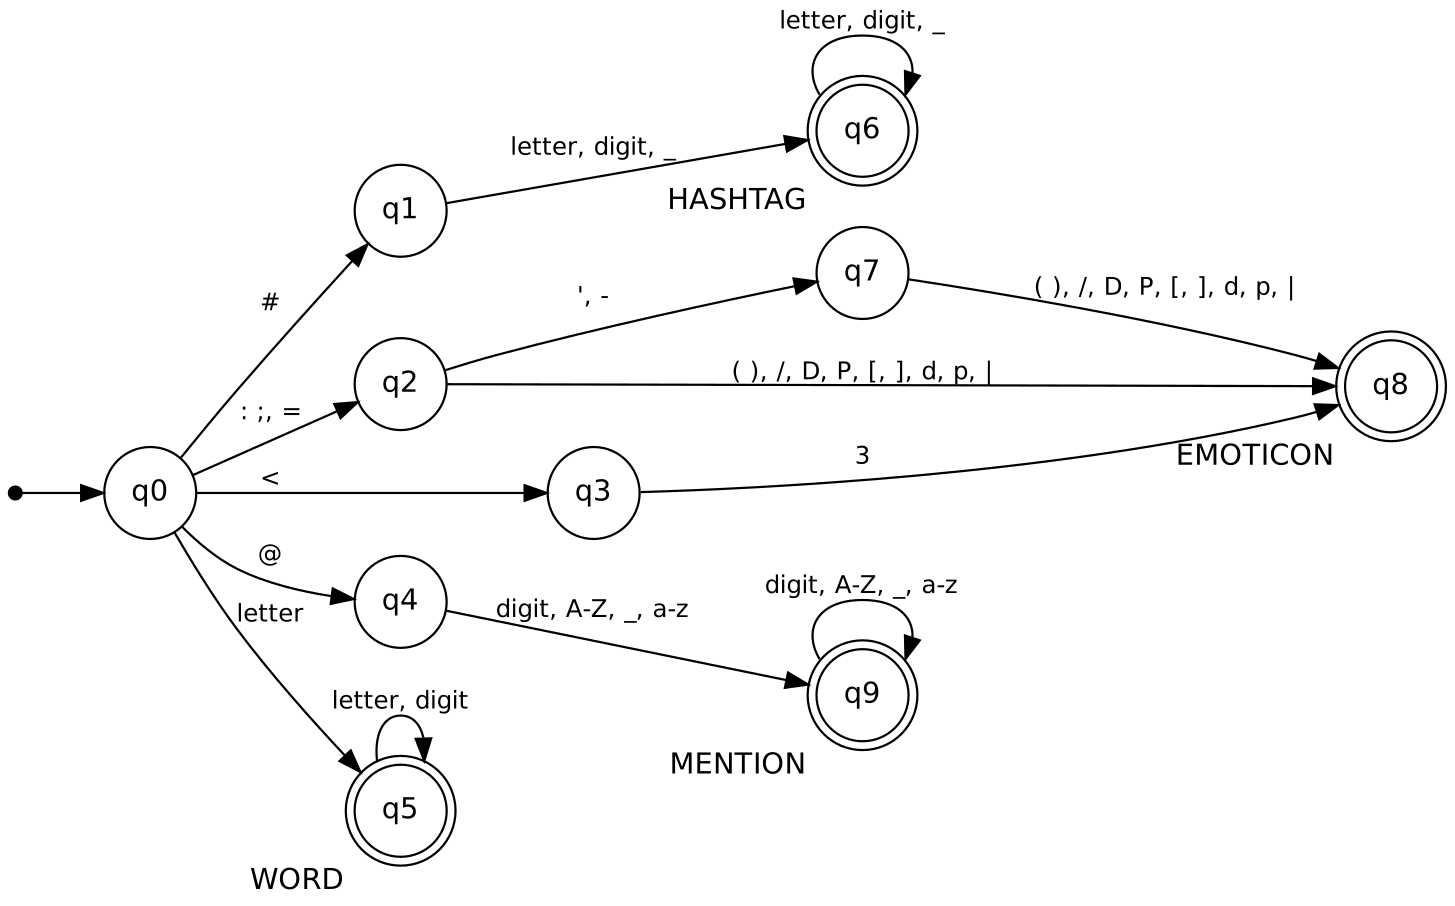

In [10]:
review1.run_module2_experiments(QUICK_MODE, force=FORCE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["dfa_states"]))
display(Image(f"{RES}/module2/dfa_min.png"))

### Observations — DFA

In [11]:
display(Markdown(observation("dfa", RES)))

- Combined automaton for MENTION, HASHTAG, EMOTICON, WORD: 43 NFA states -> 12 DFA states -> 10 after minimization (31 alphabet atoms).
- Per class (NFA / DFA / minimized): MENTION 9/3/3; HASHTAG 9/3/3; EMOTICON 19/6/5; WORD 9/3/2.
- ELONGATED is written with a back-reference (`[A-Za-z]*([A-Za-z])\1{2,}[A-Za-z]*`) and is not accepted by our regex parser, so it is not in the DFA engine. Spelled out as 26 alternatives (lowercase only) it compiles to 221 NFA / 157 DFA / 54 minimized states.

### 3d. Scanner demo with error recovery
The table-driven scanner follows the DFA as far as it can, remembers the last accepting position and backs up to it.
A character that no class accepts (here `§`) becomes an **UNKNOWN** token and scanning continues. The last line checks
that the PLY lexer restricted to the same four classes produces exactly the same tokens.

In [12]:
tokens, agree = review1.scanner_demo()
display(tokens)
print("DFA scanner and PLY lexer agree on this input:", agree)

,class,lexeme,position
0,HASHTAG,#mood,0
1,EMOTICON,:-),6
2,MENTION,@bob_1,10
3,WORD,café,17
4,UNKNOWN,§,22
5,EMOTICON,<3,24
6,WORD,w8,27


DFA scanner and PLY lexer agree on this input: True


### 3e. Intrinsic metrics
Measured on lowercased text for all four tokenizers: **OOV rate** (share of test tokens never seen in train),
**fertility** (tokens per whitespace-separated word), **vocabulary size** (distinct train tokens) and **throughput**
(tokens per second on this machine; it varies between machines).

| dataset | tokenizer | OOV rate % (tokens) | OOV rate % (types) | fertility | vocab size | throughput (tokens/s) |
|---|---|---|---|---|---|---|
| tweet_topic | whitespace | 21.13 | 53.44 | 1.000 | 14325 | 23,093,570 |
| tweet_topic | nltk | 10.35 | 43.45 | 1.425 | 10816 | 228,721 |
| tweet_topic | tweet | 11.37 | 45.27 | 1.376 | 11289 | 281,230 |
| tweet_topic | lexfront | 9.90 | 42.98 | 1.390 | 9977 | 167,021 |
| tweet_topic | bpe | 0.91 | 2.18 | 1.632 | 7210 | 566,456 |
| tweet_topic | lexfront_bpe | 2.71 | 13.73 | 1.599 | 8667 | 165,976 |
| tweet_topic | wordpiece | 0.65 | 2.43 | 1.613 | 7077 | 759,458 |
| tweet_topic | unigram | 0.29 | 1.19 | 1.873 | 5116 | 828,747 |
| go_emotions | whitespace | 17.41 | 46.59 | 1.000 | 6320 | 23,881,263 |
| go_emotions | nltk | 9.61 | 37.15 | 1.222 | 4789 | 176,353 |
| go_emotions | tweet | 9.77 | 36.49 | 1.196 | 4809 | 245,463 |
| go_emotions | lexfront | 9.61 | 36.16 | 1.195 | 4707 | 265,108 |
| go_emotions | bpe | 17.04 | 32.78 | 1.433 | 4802 | 936,782 |
| go_emotions | lexfront_bpe | 17.52 | 32.76 | 1.376 | 4707 | 220,873 |
| go_emotions | wordpiece | 16.59 | 31.54 | 1.426 | 4802 | 1,114,241 |
| go_emotions | unigram | 0.25 | 1.46 | 1.755 | 2299 | 956,079 |
| ag_news | whitespace | 13.55 | 35.98 | 1.000 | 15922 | 24,713,921 |
| ag_news | nltk | 8.78 | 29.89 | 1.170 | 12748 | 281,791 |
| ag_news | tweet | 8.54 | 29.03 | 1.164 | 12570 | 257,737 |
| ag_news | lexfront | 6.91 | 25.92 | 1.226 | 11456 | 276,533 |
| ag_news | bpe | 0.34 | 1.52 | 1.497 | 7129 | 1,027,179 |
| ag_news | lexfront_bpe | 0.37 | 1.71 | 1.459 | 7143 | 250,456 |
| ag_news | wordpiece | 0.41 | 1.83 | 1.493 | 6950 | 1,115,493 |
| ag_news | unigram | 0.18 | 1.31 | 1.810 | 5307 | 994,161 |

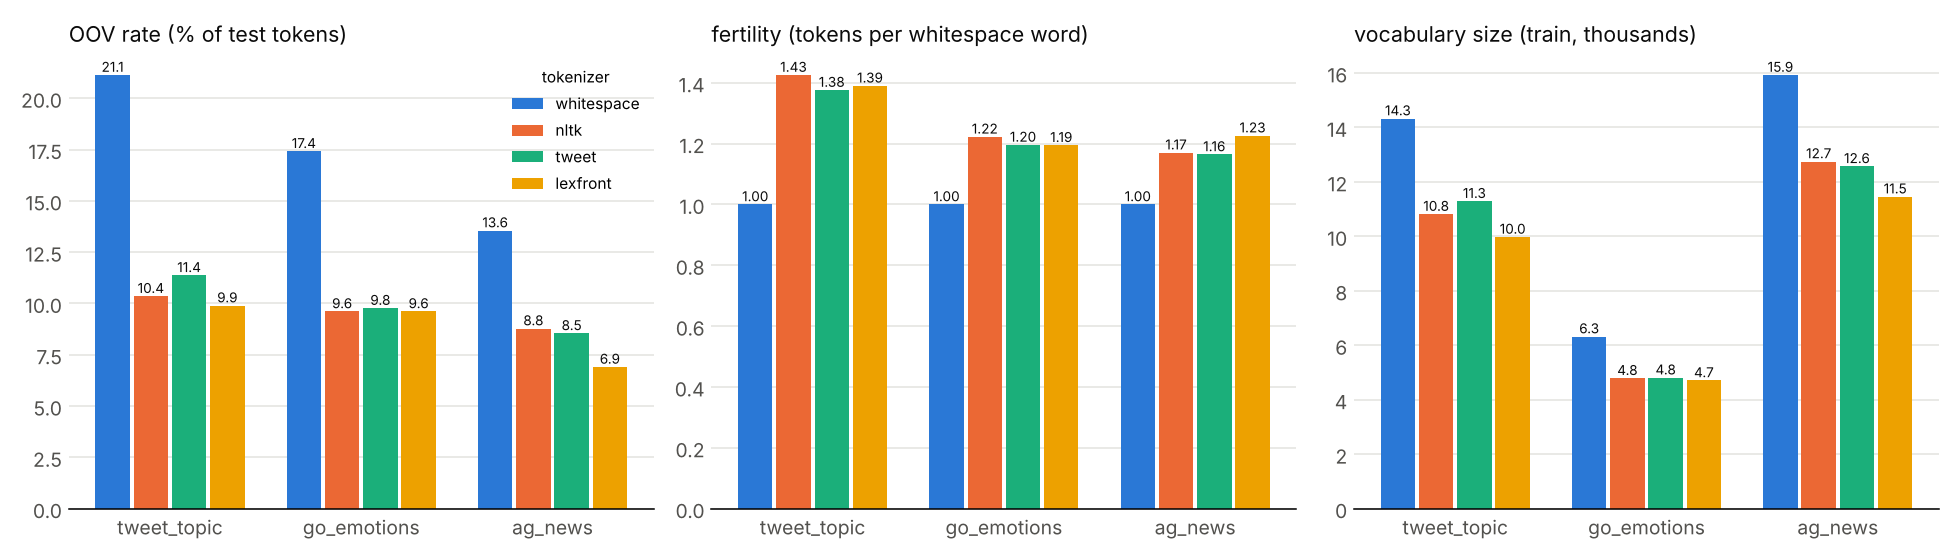

In [13]:
display(Markdown(out["tables"]["intrinsic_metrics"]))
display(Image(f"{RES}/figures/intrinsic_metrics.png"))

### Observations — intrinsic metrics

In [14]:
display(Markdown(observation("intrinsic", RES)))

- **tweet_topic**: lowest OOV rate among the word-level tokenizers 9.90% (lexfront); smallest vocabulary 9977 (lexfront); LexFront: OOV 9.90%, fertility 1.390, vocabulary 9977; LexFront throughput is 0.73x NLTK's (tokens/s, this machine). Subword tokenizers (trained on the train split; they split words into vocabulary pieces, so only characters never seen in train (`[UNK]`) and rare pieces can be OOV: the OOV rate is near zero and not comparable with the word-level ones above; LexFront + BPE splits only word-like tokens, so its OOV tokens are structural tokens passed through whole, `[UNK]`, or word pieces unseen in train): bpe: OOV 0.91%, fertility 1.632, vocabulary 7210; lexfront_bpe: OOV 2.71%, fertility 1.599, vocabulary 8667; wordpiece: OOV 0.65%, fertility 1.613, vocabulary 7077; unigram: OOV 0.29%, fertility 1.873, vocabulary 5116.
- **go_emotions**: lowest OOV rate among the word-level tokenizers 9.61% (nltk); smallest vocabulary 4707 (lexfront); LexFront: OOV 9.61%, fertility 1.195, vocabulary 4707; LexFront throughput is 1.50x NLTK's (tokens/s, this machine). Subword tokenizers (trained on the train split; they split words into vocabulary pieces, so only characters never seen in train (`[UNK]`) and rare pieces can be OOV: the OOV rate is near zero and not comparable with the word-level ones above; LexFront + BPE splits only word-like tokens, so its OOV tokens are structural tokens passed through whole, `[UNK]`, or word pieces unseen in train): bpe: OOV 17.04%, fertility 1.433, vocabulary 4802; lexfront_bpe: OOV 17.52%, fertility 1.376, vocabulary 4707; wordpiece: OOV 16.59%, fertility 1.426, vocabulary 4802; unigram: OOV 0.25%, fertility 1.755, vocabulary 2299.
- **ag_news**: lowest OOV rate among the word-level tokenizers 6.91% (lexfront); smallest vocabulary 11456 (lexfront); LexFront: OOV 6.91%, fertility 1.226, vocabulary 11456; LexFront throughput is 0.98x NLTK's (tokens/s, this machine). Subword tokenizers (trained on the train split; they split words into vocabulary pieces, so only characters never seen in train (`[UNK]`) and rare pieces can be OOV: the OOV rate is near zero and not comparable with the word-level ones above; LexFront + BPE splits only word-like tokens, so its OOV tokens are structural tokens passed through whole, `[UNK]`, or word pieces unseen in train): bpe: OOV 0.34%, fertility 1.497, vocabulary 7129; lexfront_bpe: OOV 0.37%, fertility 1.459, vocabulary 7143; wordpiece: OOV 0.41%, fertility 1.493, vocabulary 6950; unigram: OOV 0.18%, fertility 1.810, vocabulary 5307.

## 4. Existing vs proposed

**Existing** = NLTK `word_tokenize` + Naive Bayes (the method we start from). **Proposed** = LexFront + Logistic
Regression. The table also shows the two mixed cells (LexFront + NB, NLTK + LR) so a change can be attributed to the
tokenizer or to the classifier. Same TF-IDF settings and seed everywhere.

| dataset | existing NLTK+NB acc / F1 | proposed LexFront+LR acc / F1 | delta acc (pts) | delta F1 (pts) | LexFront+NB acc / F1 | NLTK+LR acc / F1 |
|---|---|---|---|---|---|---|
| tweet_topic | 66.20 / 26.64 | 66.60 / 31.30 | +0.40 | +4.66 | 66.20 / 26.68 | 66.20 / 31.70 |
| go_emotions | 35.60 / 2.91 | 43.60 / 14.06 | +8.00 | +11.15 | 35.20 / 2.41 | 43.00 / 13.90 |
| ag_news | 87.40 / 87.29 | 85.20 / 85.14 | -2.20 | -2.15 | 88.20 / 88.16 | 85.80 / 85.69 |

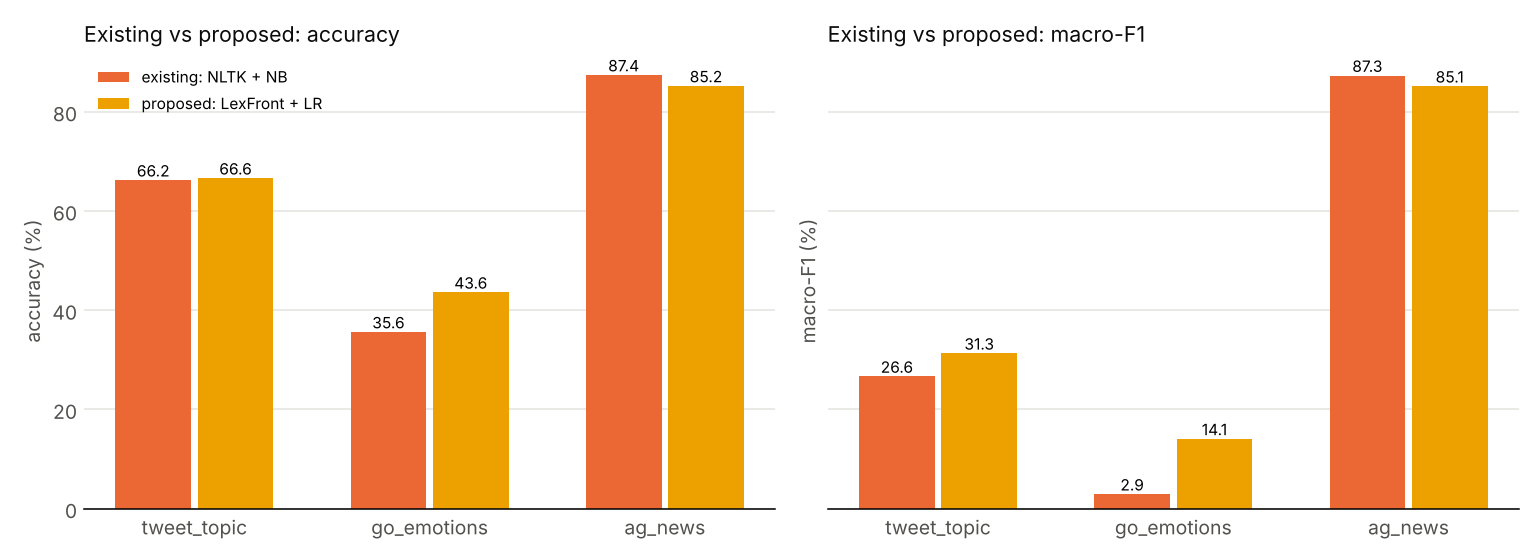

In [15]:
display(Markdown(out["tables"]["existing_vs_proposed"]))
display(Image(f"{RES}/figures/existing_vs_proposed.png"))

### Observations — existing vs proposed

In [16]:
display(Markdown(observation("existing_vs_proposed", RES)))

- **tweet_topic**: proposed (LexFront+LR) vs existing (NLTK+NB): accuracy +0.40 points, macro-F1 +4.66 points. Split of the accuracy change: switching classifier with NLTK held fixed (NB to LR) +0.00; switching tokenizer with LR held fixed (NLTK to LexFront) +0.40; switching tokenizer with NB held fixed +0.00.
- **go_emotions**: proposed (LexFront+LR) vs existing (NLTK+NB): accuracy +8.00 points, macro-F1 +11.15 points. Split of the accuracy change: switching classifier with NLTK held fixed (NB to LR) +7.40; switching tokenizer with LR held fixed (NLTK to LexFront) +0.60; switching tokenizer with NB held fixed -0.40.
- **ag_news**: proposed (LexFront+LR) vs existing (NLTK+NB): accuracy -2.20 points, macro-F1 -2.15 points. Split of the accuracy change: switching classifier with NLTK held fixed (NB to LR) -1.60; switching tokenizer with LR held fixed (NLTK to LexFront) -0.60; switching tokenizer with NB held fixed +0.80.

_One training run per cell (seed 0). The 95% confidence intervals (table `ci_table`, file `stats/bootstrap.json`) are percentile bootstraps over the test examples: they show how much a score moves with the draw of the test set, not with training randomness, which one run per cell cannot show (the NB and LR fits are deterministic; the full grid uses no subsampling, QUICK mode one fixed-seed subsample). A gap whose CI includes 0 should not be read as a real difference. Gaps not in `ci_table` (e.g. spreads between baselines, LR vs NB) have no paired CI and are untested; overlapping per-run CIs (`ci_runs`) are not a test of a difference._

## 5. Is the difference larger than test-set noise?

Every run above also saved its test predictions (`predictions/<run>.json.gz` next to its JSON). The cell below
resamples the test examples with replacement (percentile bootstrap, fixed seed; B and the seed are stored in
`stats/bootstrap.json`) and recomputes accuracy and macro-F1 from a confusion matrix for each resample. For a
difference, both systems are scored on the *same* resamples (paired); NLTK+LR vs LexFront+LR also gets an exact
McNemar test. Same code as the full grid (`python -m experiments.run_stats`), here on the QUICK grid.
QUICK uses 500 test examples per dataset (the full test sets have 3399 to 7600), so these intervals are wider (for
accuracy differences about 2 to 6 times the full-grid width in the committed runs) and a difference can even change
sign; the headline CIs are the full-grid ones in
`results/stats/bootstrap.json` (table `ci_table` in the appendix). These intervals cover the draw of the test set only, not training randomness (one training run per cell).

In [17]:
review1.run_stats_section(QUICK_MODE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["ci_table"]))
display(Markdown(out["tables"]["ci_runs"]))

wrote results/quick/stats/bootstrap.json


| dataset | difference | accuracy pts [95% CI] | macro-F1 pts [95% CI] | CI excludes 0 (acc / F1) | McNemar p (acc) |
|---|---|---|---|---|---|
| tweet_topic | LexFront+LR minus NLTK+LR (tokenizer only) | +0.40 [-1.40, +2.20] | -0.40 [-1.75, +0.79] | no / no | 0.839 |
| tweet_topic | LexFront+LR minus TweetTokenizer+LR (tokenizer only) | +1.20 [-0.60, +3.20] | +0.25 [-1.03, +1.60] | no / no | - |
| tweet_topic | LexFront+LR minus NLTK+NB (proposed minus existing) | +0.40 [-2.80, +3.40] | +4.66 [+2.21, +7.17] | no / yes | - |
| go_emotions | LexFront+LR minus NLTK+LR (tokenizer only) | +0.60 [-0.20, +1.60] | +0.16 [-0.35, +0.65] | no / no | 0.375 |
| go_emotions | LexFront+LR minus TweetTokenizer+LR (tokenizer only) | +0.60 [-0.20, +1.60] | +0.11 [-0.38, +0.60] | no / no | - |
| go_emotions | LexFront+LR minus NLTK+NB (proposed minus existing) | +8.00 [+5.40, +10.60] | +11.15 [+7.81, +14.24] | yes / yes | - |
| ag_news | LexFront+LR minus NLTK+LR (tokenizer only) | -0.60 [-2.20, +1.20] | -0.55 [-2.25, +1.17] | no / no | 0.648 |
| ag_news | LexFront+LR minus TweetTokenizer+LR (tokenizer only) | -0.80 [-2.40, +0.80] | -0.71 [-2.42, +0.92] | no / no | - |
| ag_news | LexFront+LR minus NLTK+NB (proposed minus existing) | -2.20 [-4.40, +0.00] | -2.15 [-4.39, +0.00] | no / no | - |

| dataset | tokenizer | classifier | accuracy % [95% CI] | macro-F1 % [95% CI] |
|---|---|---|---|---|
| tweet_topic | whitespace | Naive Bayes | 63.80 [59.40, 67.80] | 25.73 [23.88, 27.70] |
| tweet_topic | whitespace | Logistic Reg. | 65.60 [61.20, 69.40] | 30.78 [28.17, 33.23] |
| tweet_topic | nltk | Naive Bayes | 66.20 [61.99, 70.20] | 26.64 [24.93, 28.46] |
| tweet_topic | nltk | Logistic Reg. | 66.20 [62.00, 70.00] | 31.70 [29.08, 34.14] |
| tweet_topic | tweet | Naive Bayes | 66.40 [62.20, 70.20] | 26.77 [25.02, 28.64] |
| tweet_topic | tweet | Logistic Reg. | 65.40 [61.20, 69.01] | 31.05 [28.50, 33.49] |
| tweet_topic | lexfront | Naive Bayes | 66.20 [62.00, 70.20] | 26.68 [24.99, 28.59] |
| tweet_topic | lexfront | Logistic Reg. | 66.60 [62.40, 70.60] | 31.30 [28.68, 33.78] |
| go_emotions | whitespace | Naive Bayes | 35.40 [31.40, 39.60] | 2.64 [1.99, 3.48] |
| go_emotions | whitespace | Logistic Reg. | 41.00 [36.80, 45.20] | 10.58 [8.02, 13.47] |
| go_emotions | nltk | Naive Bayes | 35.60 [31.60, 39.80] | 2.91 [2.09, 3.93] |
| go_emotions | nltk | Logistic Reg. | 43.00 [38.60, 47.40] | 13.90 [10.79, 17.04] |
| go_emotions | tweet | Naive Bayes | 35.60 [31.60, 39.80] | 2.91 [2.09, 3.93] |
| go_emotions | tweet | Logistic Reg. | 43.00 [38.60, 47.40] | 13.94 [10.84, 17.08] |
| go_emotions | lexfront | Naive Bayes | 35.20 [31.20, 39.40] | 2.41 [1.88, 3.21] |
| go_emotions | lexfront | Logistic Reg. | 43.60 [39.20, 48.00] | 14.06 [10.97, 17.28] |
| ag_news | whitespace | Naive Bayes | 86.80 [83.80, 89.80] | 86.73 [83.60, 89.59] |
| ag_news | whitespace | Logistic Reg. | 84.80 [81.40, 88.00] | 84.72 [81.38, 87.81] |
| ag_news | nltk | Naive Bayes | 87.40 [84.40, 90.20] | 87.29 [84.16, 90.01] |
| ag_news | nltk | Logistic Reg. | 85.80 [82.60, 88.60] | 85.69 [82.31, 88.57] |
| ag_news | tweet | Naive Bayes | 88.00 [85.00, 90.80] | 87.97 [84.99, 90.62] |
| ag_news | tweet | Logistic Reg. | 86.00 [82.80, 89.00] | 85.85 [82.48, 88.78] |
| ag_news | lexfront | Naive Bayes | 88.20 [85.39, 90.80] | 88.16 [85.21, 90.76] |
| ag_news | lexfront | Logistic Reg. | 85.20 [81.99, 88.20] | 85.14 [81.78, 88.18] |

### Observations — confidence intervals

In [18]:
display(Markdown(observation("ci", RES)))

- **tweet_topic**, LexFront+LR minus NLTK+LR (tokenizer only): accuracy +0.40 points (95% CI -1.40 to +2.20, includes 0); macro-F1 -0.40 points (95% CI -1.75 to +0.79, includes 0). Exact McNemar test on accuracy: p = 0.839 (discordant test examples: right only with nltk+lr 11, right only with lexfront+lr 13).
- **tweet_topic**, LexFront+LR minus TweetTokenizer+LR (tokenizer only): accuracy +1.20 points (95% CI -0.60 to +3.20, includes 0); macro-F1 +0.25 points (95% CI -1.03 to +1.60, includes 0).
- **tweet_topic**, LexFront+LR minus NLTK+NB (proposed minus existing): accuracy +0.40 points (95% CI -2.80 to +3.40, includes 0); macro-F1 +4.66 points (95% CI +2.21 to +7.17, excludes 0).
- **go_emotions**, LexFront+LR minus NLTK+LR (tokenizer only): accuracy +0.60 points (95% CI -0.20 to +1.60, includes 0); macro-F1 +0.16 points (95% CI -0.35 to +0.65, includes 0). Exact McNemar test on accuracy: p = 0.375 (discordant test examples: right only with nltk+lr 1, right only with lexfront+lr 4).
- **go_emotions**, LexFront+LR minus TweetTokenizer+LR (tokenizer only): accuracy +0.60 points (95% CI -0.20 to +1.60, includes 0); macro-F1 +0.11 points (95% CI -0.38 to +0.60, includes 0).
- **go_emotions**, LexFront+LR minus NLTK+NB (proposed minus existing): accuracy +8.00 points (95% CI +5.40 to +10.60, excludes 0); macro-F1 +11.15 points (95% CI +7.81 to +14.24, excludes 0).
- **ag_news**, LexFront+LR minus NLTK+LR (tokenizer only): accuracy -0.60 points (95% CI -2.20 to +1.20, includes 0); macro-F1 -0.55 points (95% CI -2.25 to +1.17, includes 0). Exact McNemar test on accuracy: p = 0.648 (discordant test examples: right only with nltk+lr 11, right only with lexfront+lr 8).
- **ag_news**, LexFront+LR minus TweetTokenizer+LR (tokenizer only): accuracy -0.80 points (95% CI -2.40 to +0.80, includes 0); macro-F1 -0.71 points (95% CI -2.42 to +0.92, includes 0).
- **ag_news**, LexFront+LR minus NLTK+NB (proposed minus existing): accuracy -2.20 points (95% CI -4.40 to +0.00, includes 0); macro-F1 -2.15 points (95% CI -4.39 to +0.00, includes 0).
- Tokenizer-only comparison (LexFront+LR vs NLTK+LR): 0 of 6 difference CIs (accuracy and macro-F1, all datasets) exclude 0.
- Settings: percentile bootstrap over test examples, B = 2000, seed 20261016, 95% percentile intervals.

_One training run per cell (seed 0). The 95% confidence intervals (table `ci_table`, file `stats/bootstrap.json`) are percentile bootstraps over the test examples: they show how much a score moves with the draw of the test set, not with training randomness, which one run per cell cannot show (the NB and LR fits are deterministic; the full grid uses no subsampling, QUICK mode one fixed-seed subsample). A gap whose CI includes 0 should not be read as a real difference. Gaps not in `ci_table` (e.g. spreads between baselines, LR vs NB) have no paired CI and are untested; overlapping per-run CIs (`ci_runs`) are not a test of a difference._

## 6. Which normalization rule matters? (ablation)

LexFront's normalizer has six switchable rules (URL, MENTION, NUMBER, ELONGATED, lowercase, slang). Each variant
below is LexFront + Logistic Regression with one rule switched off, everything else fixed, compared with full
LexFront on the same resampled test examples (paired bootstrap, as in section 5; McNemar on accuracy).
*Main setting* (TF-IDF lowercases, as the main grid): no_url, no_mention, no_number, no_elongated, no_slang and
all_off (lexer segmentation only; TF-IDF still lowercases). The lowercase rule cannot show an effect there, because TF-IDF lowercases the text
before LexFront sees it, so it is tested in the *case-kept* setting (TF-IDF `lowercase=False`): no_lowercase and
all_off_cs against full_cs. On the QUICK subsample (500 test examples) these intervals are wide; the full-data
ablation is in `results/ablation/` (appendix). With up to 8 comparisons per dataset and no multiplicity correction,
an interval can exclude 0 by chance. The column "rule fires" counts the train / test documents in which the removed
rule changes a token; a rule that never fires on the subsample (0 / 0) gives the full system, not a test of the rule.

In [19]:
review1.run_ablation_section(QUICK_MODE, force=FORCE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["ablation_table"]))

== ablation tweet_topic: train=2000 test=500


tweet_topic  lexfront   lr       acc=0.6660 f1=0.3130


tweet_topic  lexfront:no_url lr       acc=0.6660 f1=0.3130


tweet_topic  lexfront:no_mention lr       acc=0.6720 f1=0.3130


tweet_topic  lexfront:no_number lr       acc=0.6520 f1=0.3091


...

ag_news      lexfront:no_lowercase lr       acc=0.8480 f1=0.8476


ag_news      lexfront:all_off lr       acc=0.8440 f1=0.8429


wrote results/quick/ablation/case/firing__ag_news.json


wrote results/quick/ablation/stats/bootstrap.json


| dataset | setting | variant | rule fires, docs train / test | TF-IDF features | acc / F1 % | acc minus full, pts [95% CI] | F1 minus full, pts [95% CI] | CI excludes 0 (acc / F1) | predictions changed | McNemar p (acc) |
|---|---|---|---|---|---|---|---|---|---|---|
| tweet_topic | TF-IDF lowercase (main grid) | full (reference) | - | 3534 | 66.60 / 31.30 | - | - | - | - | - |
| tweet_topic | TF-IDF lowercase (main grid) | no_url | 0 / 0 | 3534 | 66.60 / 31.30 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| tweet_topic | TF-IDF lowercase (main grid) | no_mention | 1335 / 349 | 3783 | 67.20 / 31.30 | +0.60 [-0.40, +1.60] | +0.00 [-0.84, +0.68] | no / no | 7 | 0.453 |
| tweet_topic | TF-IDF lowercase (main grid) | no_number | 656 / 173 | 3610 | 65.20 / 30.91 | -1.40 [-3.20, +0.20] | -0.39 [-1.62, +0.89] | no / no | 33 | 0.167 |
| tweet_topic | TF-IDF lowercase (main grid) | no_elongated | 53 / 12 | 3532 | 67.00 / 31.46 | +0.40 [+0.00, +1.00] | +0.16 [+0.00, +0.41] | no / no | 2 | 0.500 |
| tweet_topic | TF-IDF lowercase (main grid) | no_slang | 132 / 27 | 3551 | 67.20 / 31.78 | +0.60 [+0.00, +1.40] | +0.48 [+0.00, +1.23] | no / no | 5 | 0.250 |
| tweet_topic | TF-IDF lowercase (main grid) | all_off (TF-IDF still lowercases) | 1589 / 408 | 3874 | 65.40 / 30.52 | -1.20 [-3.00, +0.60] | -0.78 [-1.75, +0.08] | no / no | 27 | 0.263 |
| tweet_topic | case kept (TF-IDF lowercase=False) | full_cs (reference) | - | 3514 | 66.80 / 31.39 | - | - | - | - | - |
| tweet_topic | case kept (TF-IDF lowercase=False) | no_lowercase | 1993 / 496 | 4009 | 65.80 / 31.11 | -1.00 [-3.00, +1.00] | -0.28 [-2.06, +1.53] | no / no | 46 | 0.442 |
| tweet_topic | case kept (TF-IDF lowercase=False) | all_off_cs | 2000 / 500 | 4340 | 66.00 / 31.57 | -0.80 [-3.20, +1.80] | +0.18 [-1.66, +2.03] | no / no | 69 | 0.644 |
| go_emotions | TF-IDF lowercase (main grid) | full (reference) | - | 1779 | 43.60 / 14.06 | - | - | - | - | - |
| go_emotions | TF-IDF lowercase (main grid) | no_url | 0 / 0 | 1779 | 43.60 / 14.06 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| go_emotions | TF-IDF lowercase (main grid) | no_mention | 0 / 0 | 1779 | 43.60 / 14.06 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| go_emotions | TF-IDF lowercase (main grid) | no_number | 186 / 39 | 1813 | 43.40 / 13.90 | -0.20 [-0.60, +0.00] | -0.16 [-0.54, +0.00] | no / no | 1 | 1.000 |
| go_emotions | TF-IDF lowercase (main grid) | no_elongated | 32 / 7 | 1777 | 43.60 / 14.06 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| go_emotions | TF-IDF lowercase (main grid) | no_slang | 84 / 9 | 1791 | 43.40 / 13.90 | -0.20 [-0.60, +0.00] | -0.16 [-0.56, +0.08] | no / no | 3 | 1.000 |
| go_emotions | TF-IDF lowercase (main grid) | all_off (TF-IDF still lowercases) | 281 / 54 | 1823 | 43.40 / 13.90 | -0.20 [-0.60, +0.00] | -0.16 [-0.56, +0.08] | no / no | 3 | 1.000 |
| go_emotions | case kept (TF-IDF lowercase=False) | full_cs (reference) | - | 1779 | 43.60 / 14.06 | - | - | - | - | - |
| go_emotions | case kept (TF-IDF lowercase=False) | no_lowercase | 1900 / 482 | 1930 | 41.00 / 11.06 | -2.60 [-4.20, -1.00] | -3.00 [-5.79, -0.62] | yes / yes | 25 | 0.002 |
| go_emotions | case kept (TF-IDF lowercase=False) | all_off_cs | 1926 / 484 | 1971 | 41.00 / 11.06 | -2.60 [-4.20, -1.00] | -3.00 [-5.79, -0.62] | yes / yes | 25 | 0.002 |
| ag_news | TF-IDF lowercase (main grid) | full (reference) | - | 5450 | 85.20 / 85.14 | - | - | - | - | - |
| ag_news | TF-IDF lowercase (main grid) | no_url | 32 / 12 | 5452 | 85.20 / 85.14 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| ag_news | TF-IDF lowercase (main grid) | no_mention | 0 / 0 | 5450 | 85.20 / 85.14 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| ag_news | TF-IDF lowercase (main grid) | no_number | 862 / 234 | 5597 | 86.20 / 86.17 | +1.00 [-0.20, +2.20] | +1.03 [-0.11, +2.26] | no / no | 11 | 0.180 |
| ag_news | TF-IDF lowercase (main grid) | no_elongated | 8 / 1 | 5449 | 85.20 / 85.14 | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | 0 | 1.000 |
| ag_news | TF-IDF lowercase (main grid) | no_slang | 118 / 28 | 5452 | 85.40 / 85.37 | +0.20 [+0.00, +0.60] | +0.23 [+0.00, +0.71] | no / no | 1 | 1.000 |
| ag_news | TF-IDF lowercase (main grid) | all_off (TF-IDF still lowercases) | 943 / 254 | 5600 | 86.20 / 86.17 | +1.00 [-0.20, +2.20] | +1.03 [-0.11, +2.26] | no / no | 11 | 0.180 |
| ag_news | case kept (TF-IDF lowercase=False) | full_cs (reference) | - | 5452 | 85.20 / 85.14 | - | - | - | - | - |
| ag_news | case kept (TF-IDF lowercase=False) | no_lowercase | 2000 / 500 | 6202 | 84.80 / 84.76 | -0.40 [-2.00, +1.20] | -0.38 [-2.03, +1.28] | no / no | 22 | 0.804 |
| ag_news | case kept (TF-IDF lowercase=False) | all_off_cs | 2000 / 500 | 6350 | 84.40 / 84.29 | -0.80 [-2.80, +1.20] | -0.85 [-2.91, +1.20] | no / no | 30 | 0.557 |

### Observations — ablation

In [20]:
display(Markdown(observation("ablation", RES)))

- **tweet_topic** (7 variants vs full): accuracy CI excludes 0 for none; macro-F1 CI excludes 0 for none. Every other compared interval includes 0. Rule never fires on this data (train and test), so not a test of the rule: no_url (identical to full, left out of the counts).
- **go_emotions** (6 variants vs full): accuracy CI excludes 0 for no_lowercase (case kept) -2.60 (lower than full), all_off_cs (case kept) -2.60 (lower than full); macro-F1 CI excludes 0 for no_lowercase (case kept) -3.00 (lower than full), all_off_cs (case kept) -3.00 (lower than full). Every other compared interval includes 0. Rule never fires on this data (train and test), so not a test of the rule: no_url, no_mention (identical to full, left out of the counts).
- **ag_news** (7 variants vs full): accuracy CI excludes 0 for none; macro-F1 CI excludes 0 for none. Every other compared interval includes 0. Rule never fires on this data (train and test), so not a test of the rule: no_mention (identical to full, left out of the counts).
- In all, 4 of 40 difference CIs of the compared variants exclude 0 (4 never-firing variants left out). There is no multiplicity correction: with 40 separate 95% intervals, roughly 2.0 would exclude 0 by chance even if no rule had any effect, if the intervals were independent (they are not: all_off contains every single-rule change), so a single interval that excludes 0 is weak evidence on its own.

_Ablation: each variant is LexFront + LR with the named rule (all_off: every rule) switched off, everything else fixed; in the main setting all_off still has TF-IDF's lowercasing (TF-IDF still lowercases). Differences are variant minus full LexFront of the same setting, paired bootstrap over the test examples (same code, B and seed as `ci_table`). One training run per variant, so training randomness is not covered. The lowercase rule is tested only with case kept: in the main setting TF-IDF lowercases the text before LexFront sees it, so switching the rule off cannot change anything there. A variant whose rule never fires on a dataset (train and test) is the full system itself, so it is listed apart and not counted as a comparison; 0 changed predictions alone does not show that (a rule firing only in train still changes the fit). These numbers say which removals change the scores, not why; any reason given elsewhere is a hypothesis._

## 7. Subword tokenizers: BPE and LexFront + BPE

**BPE** (byte-pair encoding, Hugging Face `tokenizers`) learns a vocabulary of 8000 subword pieces from each dataset's
*train* split (lowercased, never the test split) and splits words into vocabulary pieces; a piece that continues a
word carries `##`. **LexFront + BPE** keeps LexFront's scanner and normalizer: structural tokens (`<URL>`, `<USER>`,
`<NUM>`, hashtags, emoticons, emoji, punctuation, UNKNOWN) pass through whole, and only word-like tokens are split by
a BPE trained on the word-like tokens of the train split. Both feed the same TF-IDF + NB / LR as before. The first
cell shows the pieces on three example tweets with a toy BPE trained on the eight example tweets (illustration only).
The second runs the grid on the QUICK subsample and the paired bootstrap against NLTK+LR and LexFront+LR (same code
as section 5); the full-data results are in `results/bpe/` (appendix). BPE's OOV rate in the intrinsic table is near
zero (only characters never seen in train and rare pieces can be OOV), so it is not comparable with the word-level tokenizers.

In [21]:
display(review1.bpe_demo())

,tweet,bpe,lexfront_bpe
0,OMG u wont believe this!!! https://t.co/abc123 @mike_93 :),[o] [##m] [##g] [u] [w] [##on] [##t] [be] [##l] [##ie] [##v] [##e] [this] [!!!] [ht] [##t] [##p] [##s] [:/] [##/] [t] [.] [co] [/] [ab] ...,[oh] [my] [god] [you] [wont] [belie] [##ve] [this] [!] [!] [!] [<URL>] [<USER>] [:)]
1,sooooo tired of mondays #monday #ugh 😩😩,[s] [##ooooo] [t] [##i] [##r] [##ed] [o] [##f] [monday] [##s] [#] [monday] [#] [u] [##gh] [😩] [##😩],[so] [##o] [ti] [##red] [of] [monday] [##s] [#monday] [#ugh] [😩] [😩]
2,"can't wait for the game tonight, we're gonna win 3-0 <3","[ca] [##n] ['] [t] [wa] [##it] [for] [the] [ga] [##m] [##e] [t] [##on] [##igh] [##t] [,] [w] [##e] ['] [r] [##e] [gon] [##n] [##a] [w] [...","[can] [##'t] [wait] [fo] [##r] [the] [ga] [##me] [tonigh] [##t] [,] [we'] [##re] [going] [to] [win] [<NUM>] [-] [<NUM>] [<3]"


In [22]:
review1.run_bpe_section(QUICK_MODE, force=FORCE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["bpe_runs"]))
display(Markdown(out["tables"]["bpe_table"]))

== tweet_topic: train=2000 test=500 labels=6


tweet_topic  bpe        nb       acc=0.6500 f1=0.2569
tweet_topic  bpe        lr       acc=0.6720 f1=0.3179


tweet_topic  lexfront_bpe nb       acc=0.6460 f1=0.2505
tweet_topic  lexfront_bpe lr       acc=0.6600 f1=0.3065


== go_emotions: train=2000 test=500 labels=28


go_emotions  bpe        nb       acc=0.3560 f1=0.0291


...

ag_news      bpe        nb       acc=0.8620 f1=0.8610
ag_news      bpe        lr       acc=0.8500 f1=0.8497


ag_news      lexfront_bpe nb       acc=0.8620 f1=0.8613
ag_news      lexfront_bpe lr       acc=0.8460 f1=0.8457


wrote results/quick/bpe/stats/bootstrap.json


| dataset | BPE vocab | BPE+NB acc / F1 | BPE+LR acc / F1 | LexFront+BPE+NB acc / F1 | LexFront+BPE+LR acc / F1 | NLTK+LR acc / F1 | LexFront+LR acc / F1 |
|---|---|---|---|---|---|---|---|
| tweet_topic | 8000 | 65.00 / 25.69 | 67.20 / 31.79 | 64.60 / 25.05 | 66.00 / 30.65 | 66.20 / 31.70 | 66.60 / 31.30 |
| go_emotions | 8000 | 35.60 / 2.91 | 43.60 / 14.41 | 35.20 / 2.41 | 44.00 / 14.37 | 43.00 / 13.90 | 43.60 / 14.06 |
| ag_news | 8000 | 86.20 / 86.10 | 85.00 / 84.97 | 86.20 / 86.13 | 84.60 / 84.57 | 85.80 / 85.69 | 85.20 / 85.14 |

| dataset | difference | accuracy pts [95% CI] | macro-F1 pts [95% CI] | CI excludes 0 (acc / F1) | McNemar p (acc) |
|---|---|---|---|---|---|
| tweet_topic | BPE+LR minus NLTK+LR (tokenizer only) | +1.00 [-1.20, +3.20] | +0.09 [-1.61, +1.82] | no / no | 0.487 |
| tweet_topic | LexFront+BPE+LR minus LexFront+LR | -0.60 [-2.20, +1.20] | -0.66 [-2.11, +0.79] | no / no | - |
| tweet_topic | LexFront+BPE+LR minus BPE+LR | -1.20 [-3.20, +0.80] | -1.14 [-2.60, +0.08] | no / no | - |
| tweet_topic | LexFront+BPE+LR minus NLTK+LR | -0.20 [-2.40, +2.00] | -1.06 [-2.93, +0.74] | no / no | - |
| go_emotions | BPE+LR minus NLTK+LR (tokenizer only) | +0.60 [-0.60, +2.00] | +0.51 [-0.11, +1.33] | no / no | 0.581 |
| go_emotions | LexFront+BPE+LR minus LexFront+LR | +0.40 [-0.40, +1.40] | +0.31 [-0.13, +0.91] | no / no | - |
| go_emotions | LexFront+BPE+LR minus BPE+LR | +0.40 [-1.00, +1.80] | -0.04 [-0.79, +0.65] | no / no | - |
| go_emotions | LexFront+BPE+LR minus NLTK+LR | +1.00 [-0.20, +2.40] | +0.47 [-0.20, +1.22] | no / no | - |
| ag_news | BPE+LR minus NLTK+LR (tokenizer only) | -0.80 [-2.80, +1.00] | -0.72 [-2.63, +1.13] | no / no | 0.541 |
| ag_news | LexFront+BPE+LR minus LexFront+LR | -0.60 [-2.00, +0.80] | -0.57 [-1.99, +0.81] | no / no | - |
| ag_news | LexFront+BPE+LR minus BPE+LR | -0.40 [-1.80, +1.00] | -0.40 [-1.82, +1.10] | no / no | - |
| ag_news | LexFront+BPE+LR minus NLTK+LR | -1.20 [-3.20, +0.80] | -1.12 [-3.05, +0.87] | no / no | - |

### Observations — BPE and the hybrid

In [23]:
display(Markdown(observation("bpe", RES)))

- **tweet_topic**: BPE+LR minus NLTK+LR (tokenizer only): accuracy +1.00 (CI includes 0), macro-F1 +0.09 (CI includes 0); LexFront+BPE+LR minus LexFront+LR: accuracy -0.60 (CI includes 0), macro-F1 -0.66 (CI includes 0); LexFront+BPE+LR minus BPE+LR: accuracy -1.20 (CI includes 0), macro-F1 -1.14 (CI includes 0); LexFront+BPE+LR minus NLTK+LR: accuracy -0.20 (CI includes 0), macro-F1 -1.06 (CI includes 0). Exact McNemar p (BPE+LR vs NLTK+LR, accuracy) = 0.487.
- **go_emotions**: BPE+LR minus NLTK+LR (tokenizer only): accuracy +0.60 (CI includes 0), macro-F1 +0.51 (CI includes 0); LexFront+BPE+LR minus LexFront+LR: accuracy +0.40 (CI includes 0), macro-F1 +0.31 (CI includes 0); LexFront+BPE+LR minus BPE+LR: accuracy +0.40 (CI includes 0), macro-F1 -0.04 (CI includes 0); LexFront+BPE+LR minus NLTK+LR: accuracy +1.00 (CI includes 0), macro-F1 +0.47 (CI includes 0). Exact McNemar p (BPE+LR vs NLTK+LR, accuracy) = 0.581.
- **ag_news**: BPE+LR minus NLTK+LR (tokenizer only): accuracy -0.80 (CI includes 0), macro-F1 -0.72 (CI includes 0); LexFront+BPE+LR minus LexFront+LR: accuracy -0.60 (CI includes 0), macro-F1 -0.57 (CI includes 0); LexFront+BPE+LR minus BPE+LR: accuracy -0.40 (CI includes 0), macro-F1 -0.40 (CI includes 0); LexFront+BPE+LR minus NLTK+LR: accuracy -1.20 (CI includes 0), macro-F1 -1.12 (CI includes 0). Exact McNemar p (BPE+LR vs NLTK+LR, accuracy) = 0.541.
- In all, 0 of 24 difference CIs exclude 0 (vocabulary 8000, B = 2000, seed 20261016).

_Subword grid: each BPE (vocabulary size in the last line) is trained on the lowercased train split of its dataset only; LexFront + BPE keeps LexFront's structural tokens whole and splits only word-like tokens. Differences are paired bootstraps over the test examples (same code, B and seed as `ci_table`), against the NLTK+LR and LexFront+LR runs of the main grid. One training run per cell, so training randomness is not covered; no multiplicity correction. These lines say which differences exclude 0 and in which direction, not why; any reason given elsewhere is a hypothesis._

## 8. WordPiece and Unigram

Two more learned vocabularies, from the same library and the same protocol as BPE: 8000 pieces per dataset, trained on
the *train* split only (lowercased), `Whitespace` pre-tokenizer, `[UNK]`. **WordPiece** grows its vocabulary by merging
the pair that most raises the likelihood of the text and encodes by greedy longest match (continuing pieces carry
`##`). **Unigram** starts from many candidate pieces, prunes them by EM and encodes by the best-scoring split (Viterbi);
it has no `##`. No hybrid with LexFront. The first cell shows the three on three example tweets (toy vocabularies
trained on the eight example tweets, illustration only). The second runs the grid on the QUICK subsample and the paired
bootstrap against NLTK+LR and BPE+LR; the full-data results are in `results/subword2/` (appendix). OOV in the intrinsic
table is near zero for these too, so it is not comparable with the word-level tokenizers.

In [24]:
display(review1.subword2_demo())

,tweet,bpe,wordpiece,unigram
0,OMG u wont believe this!!! https://t.co/abc123 @mike_93 :),[o] [##m] [##g] [u] [w] [##on] [##t] [be] [##l] [##ie] [##v] [##e] [this] [!!!] [ht] [##t] [##p] [##s] [:/] [##/] [t] [.] [co] [/] [ab] ...,[o] [##m] [##g] [u] [w] [##on] [##t] [be] [##l] [##ie] [##v] [##e] [this] [!!!] [ht] [##t] [##p] [##s] [:/] [##/] [t] [.] [co] [/] [ab] ...,[om] [g] [u] [w] [on] [t] [b] [e] [l] [i] [e] [v] [e] [th] [i] [s] [!] [!!] [ht] [t] [p] [s] [:] [/] [/] [t] [.] [co] [/] [ab] [c] [1] [...
1,sooooo tired of mondays #monday #ugh 😩😩,[s] [##ooooo] [t] [##i] [##r] [##ed] [o] [##f] [monday] [##s] [#] [monday] [#] [u] [##gh] [😩] [##😩],[s] [##ooooo] [t] [##i] [##r] [##ed] [o] [##f] [monday] [##s] [#] [monday] [#] [u] [##gh] [😩] [##😩],[s] [o] [oooo] [t] [i] [re] [d] [o] [f] [monday] [s] [#] [monday] [#] [u] [gh] [😩] [😩]
2,"can't wait for the game tonight, we're gonna win 3-0 <3","[ca] [##n] ['] [t] [wa] [##it] [for] [the] [ga] [##m] [##e] [t] [##on] [##igh] [##t] [,] [w] [##e] ['] [r] [##e] [gon] [##n] [##a] [w] [...","[ca] [##n] ['] [t] [wa] [##it] [for] [the] [ga] [##m] [##e] [t] [##on] [##igh] [##t] [,] [w] [##e] ['] [r] [##e] [gon] [##n] [##a] [w] [...","[c] [an] ['] [t] [wa] [it] [f] [or] [th] [e] [g] [a] [me] [t] [on] [igh] [t] [,] [w] [e] ['] [re] [g] [on] [n] [a] [w] [in] [3] [-] [0] ..."


In [25]:
review1.run_subword2_section(QUICK_MODE, force=FORCE)
out = review1.build_outputs(QUICK_MODE)
display(Markdown(out["tables"]["subword_runs"]))
display(Markdown(out["tables"]["subword_table"]))

== tweet_topic: train=2000 test=500 labels=6


tweet_topic  wordpiece  nb       acc=0.6600 f1=0.2555
tweet_topic  wordpiece  lr       acc=0.6640 f1=0.3164


tweet_topic  unigram    nb       acc=0.6640 f1=0.2670
tweet_topic  unigram    lr       acc=0.6900 f1=0.3386


== go_emotions: train=2000 test=500 labels=28


go_emotions  wordpiece  nb       acc=0.3560 f1=0.0291


...

ag_news      wordpiece  nb       acc=0.8700 f1=0.8685
ag_news      wordpiece  lr       acc=0.8600 f1=0.8594


ag_news      unigram    nb       acc=0.8600 f1=0.8600
ag_news      unigram    lr       acc=0.8460 f1=0.8453


wrote results/quick/subword2/stats/bootstrap.json


| dataset | vocab | WordPiece+NB acc / F1 | WordPiece+LR acc / F1 | Unigram+NB acc / F1 | Unigram+LR acc / F1 | NLTK+LR acc / F1 | BPE+LR acc / F1 |
|---|---|---|---|---|---|---|---|
| tweet_topic | 8000 | 66.00 / 25.55 | 66.40 / 31.64 | 66.40 / 26.70 | 69.00 / 33.86 | 66.20 / 31.70 | 67.20 / 31.79 |
| go_emotions | 8000 | 35.60 / 2.91 | 43.60 / 14.41 | 35.40 / 2.64 | 43.40 / 11.99 | 43.00 / 13.90 | 43.60 / 14.41 |
| ag_news | 8000 | 87.00 / 86.85 | 86.00 / 85.94 | 86.00 / 86.00 | 84.60 / 84.53 | 85.80 / 85.69 | 85.00 / 84.97 |

| dataset | difference | accuracy pts [95% CI] | macro-F1 pts [95% CI] | CI excludes 0 (acc / F1) | McNemar p (acc) |
|---|---|---|---|---|---|
| tweet_topic | WordPiece+LR minus NLTK+LR (tokenizer only) | +0.20 [-2.00, +2.60] | -0.06 [-1.80, +1.74] | no / no | 1.000 |
| tweet_topic | Unigram+LR minus NLTK+LR (tokenizer only) | +2.80 [+0.20, +5.40] | +2.16 [+0.29, +4.17] | yes / yes | 0.054 |
| tweet_topic | WordPiece+LR minus BPE+LR | -0.80 [-2.60, +1.00] | -0.15 [-1.57, +1.34] | no / no | - |
| tweet_topic | Unigram+LR minus BPE+LR | +1.80 [-0.60, +4.40] | +2.07 [+0.19, +4.12] | no / yes | - |
| tweet_topic | Unigram+LR minus WordPiece+LR | +2.60 [+0.20, +5.20] | +2.22 [+0.43, +4.14] | yes / yes | - |
| go_emotions | WordPiece+LR minus NLTK+LR (tokenizer only) | +0.60 [-0.60, +2.00] | +0.51 [-0.11, +1.33] | no / no | 0.581 |
| go_emotions | Unigram+LR minus NLTK+LR (tokenizer only) | +0.40 [-1.40, +2.20] | -1.91 [-4.10, +0.78] | no / no | 0.832 |
| go_emotions | WordPiece+LR minus BPE+LR | +0.00 [+0.00, +0.00] | +0.00 [+0.00, +0.00] | no / no | - |
| go_emotions | Unigram+LR minus BPE+LR | -0.20 [-2.00, +1.60] | -2.42 [-4.66, +0.30] | no / no | - |
| go_emotions | Unigram+LR minus WordPiece+LR | -0.20 [-2.00, +1.60] | -2.42 [-4.66, +0.30] | no / no | - |
| ag_news | WordPiece+LR minus NLTK+LR (tokenizer only) | +0.20 [-1.40, +2.00] | +0.25 [-1.49, +2.03] | no / no | 1.000 |
| ag_news | Unigram+LR minus NLTK+LR (tokenizer only) | -1.20 [-3.20, +0.80] | -1.16 [-3.11, +0.84] | no / no | 0.327 |
| ag_news | WordPiece+LR minus BPE+LR | +1.00 [-0.60, +2.60] | +0.97 [-0.63, +2.63] | no / no | - |
| ag_news | Unigram+LR minus BPE+LR | -0.40 [-2.60, +2.00] | -0.44 [-2.61, +1.86] | no / no | - |
| ag_news | Unigram+LR minus WordPiece+LR | -1.40 [-3.40, +0.80] | -1.41 [-3.56, +0.79] | no / no | - |

### Observations — WordPiece and Unigram

In [26]:
display(Markdown(observation("subword", RES)))

- **tweet_topic**: WordPiece+LR minus NLTK+LR (tokenizer only): accuracy +0.20 (CI includes 0), macro-F1 -0.06 (CI includes 0); Unigram+LR minus NLTK+LR (tokenizer only): accuracy +2.80 (CI excludes 0, higher), macro-F1 +2.16 (CI excludes 0, higher); WordPiece+LR minus BPE+LR: accuracy -0.80 (CI includes 0), macro-F1 -0.15 (CI includes 0); Unigram+LR minus BPE+LR: accuracy +1.80 (CI includes 0), macro-F1 +2.07 (CI excludes 0, higher); Unigram+LR minus WordPiece+LR: accuracy +2.60 (CI excludes 0, higher), macro-F1 +2.22 (CI excludes 0, higher). Exact McNemar p (accuracy): WordPiece+LR vs NLTK+LR = 1.000; Unigram+LR vs NLTK+LR = 0.054.
- **go_emotions**: WordPiece+LR minus NLTK+LR (tokenizer only): accuracy +0.60 (CI includes 0), macro-F1 +0.51 (CI includes 0); Unigram+LR minus NLTK+LR (tokenizer only): accuracy +0.40 (CI includes 0), macro-F1 -1.91 (CI includes 0); WordPiece+LR minus BPE+LR: accuracy +0.00 (CI includes 0), macro-F1 +0.00 (CI includes 0); Unigram+LR minus BPE+LR: accuracy -0.20 (CI includes 0), macro-F1 -2.42 (CI includes 0); Unigram+LR minus WordPiece+LR: accuracy -0.20 (CI includes 0), macro-F1 -2.42 (CI includes 0). Exact McNemar p (accuracy): WordPiece+LR vs NLTK+LR = 0.581; Unigram+LR vs NLTK+LR = 0.832.
- **ag_news**: WordPiece+LR minus NLTK+LR (tokenizer only): accuracy +0.20 (CI includes 0), macro-F1 +0.25 (CI includes 0); Unigram+LR minus NLTK+LR (tokenizer only): accuracy -1.20 (CI includes 0), macro-F1 -1.16 (CI includes 0); WordPiece+LR minus BPE+LR: accuracy +1.00 (CI includes 0), macro-F1 +0.97 (CI includes 0); Unigram+LR minus BPE+LR: accuracy -0.40 (CI includes 0), macro-F1 -0.44 (CI includes 0); Unigram+LR minus WordPiece+LR: accuracy -1.40 (CI includes 0), macro-F1 -1.41 (CI includes 0). Exact McNemar p (accuracy): WordPiece+LR vs NLTK+LR = 1.000; Unigram+LR vs NLTK+LR = 0.327.
- In all, 5 of 30 difference CIs exclude 0 (B = 2000, seed 20261016).

_WordPiece and Unigram (vocabulary 8000, `Whitespace` pre-tokenizer) are each trained on the lowercased train split of their dataset only, and feed the same TF-IDF + LR / NB as the other tokenizers. Differences are paired bootstraps over the test examples (same code, B and seed as `ci_table`) against the NLTK+LR run of the main grid and the BPE+LR run of the P3 grid. One training run per cell, so training randomness is not covered; no multiplicity correction. These lines say which differences exclude 0 and in which direction, not why; any reason given elsewhere is a hypothesis._

## Appendix — committed full-data results
The tables below are built from the JSON files in `results/` (full datasets, produced by
`python -m experiments.run_module1`, `python -m experiments.run_module2`, `python -m experiments.run_stats` and
`python -m experiments.run_sensitivity`, `python -m experiments.run_ablation`, `python -m experiments.run_bpe`, `python -m experiments.run_subword2`). `sensitivity_case` is the grid with TF-IDF `lowercase=False`: LexFront's
lowercase rule is active there while the baselines keep case, so it is a robustness check, not a like-for-like.

In [27]:
import os
if os.path.exists("results/datasets.json") and os.path.isdir("results/module1"):
    full = report.render_all_tables("results")      # read only: does not rewrite results/tables
    for name in ["module1_results", "existing_vs_proposed", "intrinsic_metrics", "ci_table", "sensitivity_case",
                 "sensitivity_ci", "ablation_table", "bpe_runs", "bpe_table", "subword_runs", "subword_table"]:
        print(name); display(Markdown(full[name]))
else:
    print("full-data results are not in this checkout")

module1_results


| dataset | tokenizer | Majority acc / F1 | Naive Bayes acc / F1 | Logistic Reg. acc / F1 |
|---|---|---|---|---|
| tweet_topic | whitespace | 40.01 / 9.53 | 70.26 / 28.83 | 70.49 / 35.76 |
| tweet_topic | nltk | 40.01 / 9.53 | 70.99 / 28.56 | 72.32 / 36.95 |
| tweet_topic | tweet | 40.01 / 9.53 | 70.79 / 28.31 | 72.02 / 36.70 |
| go_emotions | whitespace | 34.99 / 1.85 | 37.73 / 4.93 | 53.51 / 31.40 |
| go_emotions | nltk | 34.99 / 1.85 | 37.78 / 4.88 | 55.27 / 33.86 |
| go_emotions | tweet | 34.99 / 1.85 | 37.80 / 4.86 | 55.47 / 34.02 |
| ag_news | whitespace | 25.00 / 10.00 | 90.14 / 90.12 | 91.43 / 91.42 |
| ag_news | nltk | 25.00 / 10.00 | 90.38 / 90.35 | 91.88 / 91.87 |
| ag_news | tweet | 25.00 / 10.00 | 90.22 / 90.20 | 91.84 / 91.83 |

existing_vs_proposed


| dataset | existing NLTK+NB acc / F1 | proposed LexFront+LR acc / F1 | delta acc (pts) | delta F1 (pts) | LexFront+NB acc / F1 | NLTK+LR acc / F1 |
|---|---|---|---|---|---|---|
| tweet_topic | 70.99 / 28.56 | 70.73 / 36.18 | -0.26 | +7.62 | 70.43 / 27.84 | 72.32 / 36.95 |
| go_emotions | 37.78 / 4.88 | 55.36 / 33.97 | +17.58 | +29.09 | 37.78 / 4.81 | 55.27 / 33.86 |
| ag_news | 90.38 / 90.35 | 91.88 / 91.86 | +1.50 | +1.51 | 90.08 / 90.05 | 91.88 / 91.87 |

intrinsic_metrics


...

| dataset | difference | accuracy pts [95% CI] | macro-F1 pts [95% CI] | CI excludes 0 (acc / F1) | McNemar p (acc) |
|---|---|---|---|---|---|
| tweet_topic | BPE+LR minus NLTK+LR (tokenizer only) | -0.41 [-1.27, +0.44] | -1.86 [-3.28, -0.40] | no / yes | 0.397 |
| tweet_topic | LexFront+BPE+LR minus LexFront+LR | -0.82 [-1.56, -0.06] | -2.62 [-3.90, -1.46] | yes / yes | - |
| tweet_topic | LexFront+BPE+LR minus BPE+LR | -2.00 [-2.91, -1.09] | -1.53 [-2.72, -0.32] | yes / yes | - |
| tweet_topic | LexFront+BPE+LR minus NLTK+LR | -2.41 [-3.35, -1.50] | -3.39 [-4.66, -2.16] | yes / yes | - |
| go_emotions | BPE+LR minus NLTK+LR (tokenizer only) | -0.04 [-0.68, +0.59] | -0.57 [-1.37, +0.19] | no / no | 0.946 |
| go_emotions | LexFront+BPE+LR minus LexFront+LR | -0.72 [-1.31, -0.15] | -1.39 [-2.16, -0.68] | yes / yes | - |
| go_emotions | LexFront+BPE+LR minus BPE+LR | -0.59 [-1.09, -0.09] | -0.71 [-1.42, +0.00] | yes / no | - |
| go_emotions | LexFront+BPE+LR minus NLTK+LR | -0.63 [-1.24, +0.00] | -1.27 [-2.11, -0.46] | no / yes | - |
| ag_news | BPE+LR minus NLTK+LR (tokenizer only) | -0.75 [-1.13, -0.37] | -0.75 [-1.14, -0.37] | yes / yes | < 0.001 |
| ag_news | LexFront+BPE+LR minus LexFront+LR | -0.86 [-1.25, -0.49] | -0.86 [-1.25, -0.48] | yes / yes | - |
| ag_news | LexFront+BPE+LR minus BPE+LR | -0.11 [-0.38, +0.18] | -0.11 [-0.39, +0.17] | no / no | - |
| ag_news | LexFront+BPE+LR minus NLTK+LR | -0.86 [-1.28, -0.43] | -0.86 [-1.29, -0.44] | yes / yes | - |

subword_runs


| dataset | vocab | WordPiece+NB acc / F1 | WordPiece+LR acc / F1 | Unigram+NB acc / F1 | Unigram+LR acc / F1 | NLTK+LR acc / F1 | BPE+LR acc / F1 |
|---|---|---|---|---|---|---|---|
| tweet_topic | 8000 | 70.84 / 28.07 | 71.61 / 34.88 | 71.52 / 28.46 | 73.05 / 36.49 | 72.32 / 36.95 | 71.90 / 35.09 |
| go_emotions | 8000 | 38.69 / 5.67 | 55.12 / 33.12 | 38.13 / 5.18 | 55.71 / 35.12 | 55.27 / 33.86 | 55.23 / 33.29 |
| ag_news | 8000 | 88.95 / 88.89 | 91.47 / 91.46 | 89.16 / 89.12 | 90.97 / 90.96 | 91.88 / 91.87 | 91.13 / 91.12 |

subword_table


| dataset | difference | accuracy pts [95% CI] | macro-F1 pts [95% CI] | CI excludes 0 (acc / F1) | McNemar p (acc) |
|---|---|---|---|---|---|
| tweet_topic | WordPiece+LR minus NLTK+LR (tokenizer only) | -0.71 [-1.62, +0.12] | -2.08 [-3.33, -0.87] | no / yes | 0.122 |
| tweet_topic | Unigram+LR minus NLTK+LR (tokenizer only) | +0.74 [-0.24, +1.68] | -0.46 [-1.93, +0.98] | no / no | 0.143 |
| tweet_topic | WordPiece+LR minus BPE+LR | -0.29 [-0.91, +0.29] | -0.21 [-1.08, +0.70] | no / no | - |
| tweet_topic | Unigram+LR minus BPE+LR | +1.15 [+0.24, +2.09] | +1.40 [+0.09, +2.81] | yes / yes | - |
| tweet_topic | Unigram+LR minus WordPiece+LR | +1.44 [+0.56, +2.41] | +1.62 [+0.62, +2.80] | yes / yes | - |
| go_emotions | WordPiece+LR minus NLTK+LR (tokenizer only) | -0.15 [-0.78, +0.48] | -0.74 [-1.57, +0.08] | no / no | 0.687 |
| go_emotions | Unigram+LR minus NLTK+LR (tokenizer only) | +0.44 [-0.28, +1.15] | +1.26 [+0.10, +2.39] | no / yes | 0.266 |
| go_emotions | WordPiece+LR minus BPE+LR | -0.11 [-0.46, +0.26] | -0.17 [-0.62, +0.30] | no / no | - |
| go_emotions | Unigram+LR minus BPE+LR | +0.48 [-0.15, +1.11] | +1.83 [+0.78, +2.96] | no / yes | - |
| go_emotions | Unigram+LR minus WordPiece+LR | +0.59 [-0.04, +1.24] | +2.00 [+0.89, +3.14] | no / yes | - |
| ag_news | WordPiece+LR minus NLTK+LR (tokenizer only) | -0.41 [-0.82, -0.01] | -0.41 [-0.82, -0.02] | yes / yes | 0.049 |
| ag_news | Unigram+LR minus NLTK+LR (tokenizer only) | -0.91 [-1.34, -0.50] | -0.91 [-1.34, -0.50] | yes / yes | < 0.001 |
| ag_news | WordPiece+LR minus BPE+LR | +0.34 [+0.05, +0.66] | +0.34 [+0.05, +0.65] | yes / yes | - |
| ag_news | Unigram+LR minus BPE+LR | -0.16 [-0.57, +0.22] | -0.16 [-0.56, +0.22] | no / no | - |
| ag_news | Unigram+LR minus WordPiece+LR | -0.50 [-0.89, -0.13] | -0.50 [-0.89, -0.13] | yes / yes | - |